# gcn vs gat: does graph noise break them differently?
simple pilot experiment on cora - compare gcn and gat when we add or remove random edges

install pytorch geometric

In [1]:
!pip install torch_geometric -q

import everything we need

In [2]:
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.datasets import Planetoid
from torch_geometric.nn import GCNConv, GATConv

/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


set seed and pick device

In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


load the cora dataset

In [4]:
dataset = Planetoid(root="data/Planetoid", name="Cora")
data = dataset[0].to(device)
num_classes = dataset.num_classes

Processing...


/usr/local/lib/python3.11/dist-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/usr/local/lib/python3.11/dist-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/usr/local/lib/python3.11/dist-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/usr/local/lib/python3.11/dist-packages/torch_geometric/io/planetoid.py:107: VisibleDepreca

/usr/local/lib/python3.11/dist-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/usr/local/lib/python3.11/dist-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')


Done!


look at basic info about the graph

In [5]:
print(data)
print("num nodes:", data.num_nodes)
print("num edges:", data.edge_index.shape[1])
print("num features:", dataset.num_features)
print("num classes:", num_classes)
print("train nodes:", int(data.train_mask.sum()))
print("val nodes:", int(data.val_mask.sum()))
print("test nodes:", int(data.test_mask.sum()))

Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])
num nodes: 2708
num edges: 10556
num features: 1433
num classes: 7
train nodes: 140
val nodes: 500
test nodes: 1000


define a simple gcn model with two gcn layers

In [6]:
class GCN(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        return x

define a simple gat model with two attention layers

In [7]:
class GAT(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, heads=8):
        super().__init__()
        self.conv1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=0.6)
        self.conv2 = GATConv(hidden_channels * heads, out_channels, heads=1, concat=False, dropout=0.6)

    def forward(self, x, edge_index):
        x = F.dropout(x, p=0.6, training=self.training)
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=0.6, training=self.training)
        x = self.conv2(x, edge_index)
        return x

write one function to train a model and one to test it

In [8]:
def train_model(model, edge_index, epochs=100):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    start = time.time()
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(data.x, edge_index)
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()
    train_time = time.time() - start
    return train_time


@torch.no_grad()
def test_model(model, edge_index):
    model.eval()
    pred = model(data.x, edge_index).argmax(dim=1)
    acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item()
    return acc

train gcn and gat on the clean graph (no noise yet) and compare

In [9]:
set_seed(0)
gcn_clean = GCN(dataset.num_features, 16, num_classes).to(device)
gcn_time = train_model(gcn_clean, data.edge_index)
gcn_clean_acc = test_model(gcn_clean, data.edge_index)

set_seed(0)
gat_clean = GAT(dataset.num_features, 8, num_classes).to(device)
gat_time = train_model(gat_clean, data.edge_index)
gat_clean_acc = test_model(gat_clean, data.edge_index)

print(f"gcn clean accuracy: {gcn_clean_acc:.4f}  |  training time: {gcn_time:.2f}s")
print(f"gat clean accuracy: {gat_clean_acc:.4f}  |  training time: {gat_time:.2f}s")

gcn clean accuracy: 0.8040  |  training time: 1.99s
gat clean accuracy: 0.7980  |  training time: 7.25s


plot clean accuracy and training time side by side

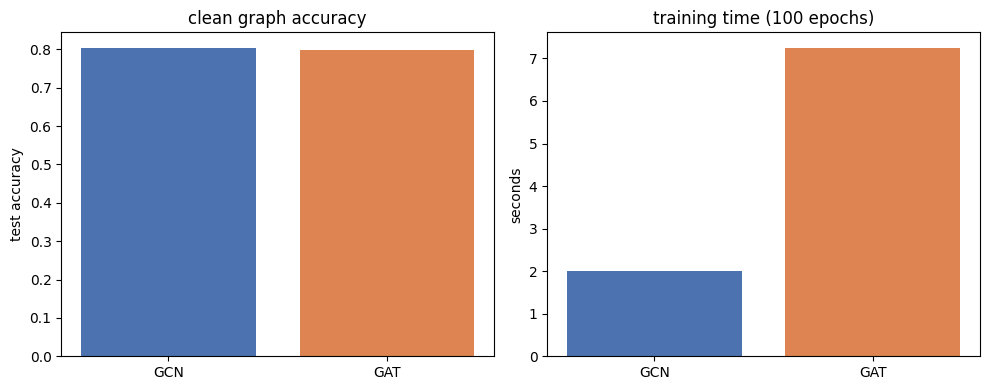

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(["GCN", "GAT"], [gcn_clean_acc, gat_clean_acc], color=["#4C72B0", "#DD8452"])
axes[0].set_ylabel("test accuracy")
axes[0].set_title("clean graph accuracy")
axes[1].bar(["GCN", "GAT"], [gcn_time, gat_time], color=["#4C72B0", "#DD8452"])
axes[1].set_ylabel("seconds")
axes[1].set_title("training time (100 epochs)")
plt.tight_layout()
plt.show()

function to add random noisy edges to the graph

In [11]:
def add_random_edges(edge_index, num_nodes, fraction, seed):
    rng = np.random.default_rng(seed)
    num_new = int(edge_index.shape[1] // 2 * fraction)
    new_edges = rng.integers(0, num_nodes, size=(num_new, 2))
    new_edges = torch.tensor(new_edges, dtype=torch.long).t()
    new_edges_reverse = new_edges.flip(0)
    return torch.cat([edge_index, new_edges, new_edges_reverse], dim=1)

function to remove random real edges from the graph

In [12]:
def remove_random_edges(edge_index, fraction, seed):
    rng = np.random.default_rng(seed)
    num_edges = edge_index.shape[1]
    num_keep = int(num_edges * (1 - fraction))
    keep_idx = rng.choice(num_edges, size=num_keep, replace=False)
    return edge_index[:, keep_idx]

noise levels we will test: 0%, 10%, 20%, 30%, 40%

In [13]:
NOISE_LEVELS = [0.0, 0.10, 0.20, 0.30, 0.40]

run the edge addition experiment: train gcn and gat again at every noise level

In [14]:
addition_results = []
for level in NOISE_LEVELS:
    noisy_edges = add_random_edges(data.edge_index, data.num_nodes, level, seed=0).to(device)

    set_seed(0)
    gcn = GCN(dataset.num_features, 16, num_classes).to(device)
    train_model(gcn, noisy_edges)
    gcn_acc = test_model(gcn, noisy_edges)

    set_seed(0)
    gat = GAT(dataset.num_features, 8, num_classes).to(device)
    train_model(gat, noisy_edges)
    gat_acc = test_model(gat, noisy_edges)

    addition_results.append({"noise_level": level, "gcn_acc": gcn_acc, "gat_acc": gat_acc})
    print(f"added {level:.0%} noisy edges -> gcn acc: {gcn_acc:.4f}, gat acc: {gat_acc:.4f}")

addition_df = pd.DataFrame(addition_results)
addition_df

added 0% noisy edges -> gcn acc: 0.8040, gat acc: 0.7980


added 10% noisy edges -> gcn acc: 0.7650, gat acc: 0.7520


added 20% noisy edges -> gcn acc: 0.7430, gat acc: 0.7440


added 30% noisy edges -> gcn acc: 0.7290, gat acc: 0.7050


added 40% noisy edges -> gcn acc: 0.7150, gat acc: 0.6940


,noise_level,gcn_acc,gat_acc
0,0.0,0.804,0.798
1,0.1,0.765,0.752
2,0.2,0.743,0.744
3,0.3,0.729,0.705
4,0.4,0.715,0.694


plot accuracy vs percentage of edges added

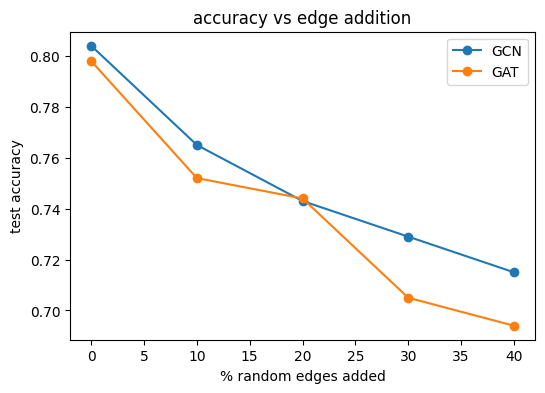

In [15]:
plt.figure(figsize=(6, 4))
plt.plot(addition_df["noise_level"] * 100, addition_df["gcn_acc"], marker="o", label="GCN")
plt.plot(addition_df["noise_level"] * 100, addition_df["gat_acc"], marker="o", label="GAT")
plt.xlabel("% random edges added")
plt.ylabel("test accuracy")
plt.title("accuracy vs edge addition")
plt.legend()
plt.show()

run the edge removal experiment: train gcn and gat again at every noise level

In [16]:
removal_results = []
for level in NOISE_LEVELS:
    fewer_edges = remove_random_edges(data.edge_index, level, seed=0).to(device)

    set_seed(0)
    gcn = GCN(dataset.num_features, 16, num_classes).to(device)
    train_model(gcn, fewer_edges)
    gcn_acc = test_model(gcn, fewer_edges)

    set_seed(0)
    gat = GAT(dataset.num_features, 8, num_classes).to(device)
    train_model(gat, fewer_edges)
    gat_acc = test_model(gat, fewer_edges)

    removal_results.append({"noise_level": level, "gcn_acc": gcn_acc, "gat_acc": gat_acc})
    print(f"removed {level:.0%} of edges -> gcn acc: {gcn_acc:.4f}, gat acc: {gat_acc:.4f}")

removal_df = pd.DataFrame(removal_results)
removal_df

removed 0% of edges -> gcn acc: 0.8040, gat acc: 0.7950


removed 10% of edges -> gcn acc: 0.8010, gat acc: 0.8080


removed 20% of edges -> gcn acc: 0.7740, gat acc: 0.7740


removed 30% of edges -> gcn acc: 0.7780, gat acc: 0.7630


removed 40% of edges -> gcn acc: 0.7510, gat acc: 0.7590


,noise_level,gcn_acc,gat_acc
0,0.0,0.804,0.795
1,0.1,0.801,0.808
2,0.2,0.774,0.774
3,0.3,0.778,0.763
4,0.4,0.751,0.759


plot accuracy vs percentage of edges removed

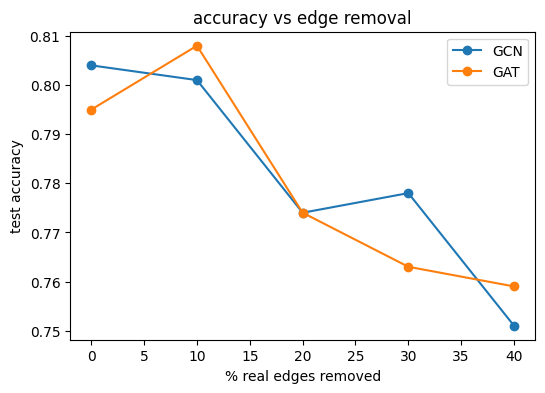

In [17]:
plt.figure(figsize=(6, 4))
plt.plot(removal_df["noise_level"] * 100, removal_df["gcn_acc"], marker="o", label="GCN")
plt.plot(removal_df["noise_level"] * 100, removal_df["gat_acc"], marker="o", label="GAT")
plt.xlabel("% real edges removed")
plt.ylabel("test accuracy")
plt.title("accuracy vs edge removal")
plt.legend()
plt.show()

function to check homophily: how often two connected nodes share the same label

In [18]:
def homophily(edge_index, labels):
    src, dst = edge_index
    same = (labels[src] == labels[dst]).float()
    return same.mean().item()

check homophily on the clean graph and on the noisiest graphs we made

In [19]:
clean_homophily = homophily(data.edge_index, data.y)
noisy_add_homophily = homophily(add_random_edges(data.edge_index, data.num_nodes, 0.40, seed=0).to(device), data.y)
noisy_remove_homophily = homophily(remove_random_edges(data.edge_index, 0.40, seed=0).to(device), data.y)

print(f"clean graph homophily: {clean_homophily:.4f}")
print(f"after 40% edges added: {noisy_add_homophily:.4f}")
print(f"after 40% edges removed: {noisy_remove_homophily:.4f}")

clean graph homophily: 0.8100
after 40% edges added: 0.6281
after 40% edges removed: 0.8126


plot homophily comparison

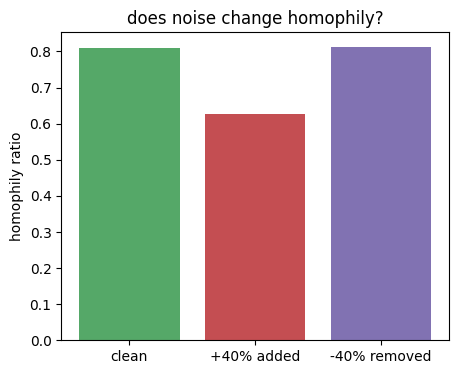

In [20]:
plt.figure(figsize=(5, 4))
plt.bar(["clean", "+40% added", "-40% removed"],
        [clean_homophily, noisy_add_homophily, noisy_remove_homophily],
        color=["#55A868", "#C44E52", "#8172B2"])
plt.ylabel("homophily ratio")
plt.title("does noise change homophily?")
plt.show()

print a short summary of everything we found

In [21]:
print("SUMMARY")
print("-------")
print(f"clean accuracy      : gcn = {gcn_clean_acc:.4f}, gat = {gat_clean_acc:.4f}")
print(f"training time       : gcn = {gcn_time:.2f}s, gat = {gat_time:.2f}s")
print(f"acc at 40% added    : gcn = {addition_df['gcn_acc'].iloc[-1]:.4f}, gat = {addition_df['gat_acc'].iloc[-1]:.4f}")
print(f"acc at 40% removed  : gcn = {removal_df['gcn_acc'].iloc[-1]:.4f}, gat = {removal_df['gat_acc'].iloc[-1]:.4f}")
print(f"homophily change    : clean = {clean_homophily:.4f}, +40% added = {noisy_add_homophily:.4f}, -40% removed = {noisy_remove_homophily:.4f}")

SUMMARY
-------
clean accuracy      : gcn = 0.8040, gat = 0.7980
training time       : gcn = 1.99s, gat = 7.25s
acc at 40% added    : gcn = 0.7150, gat = 0.6940
acc at 40% removed  : gcn = 0.7510, gat = 0.7590
homophily change    : clean = 0.8100, +40% added = 0.6281, -40% removed = 0.8126
